# Notebook 05 - Anomaly injection (sensor faults vs. grid events)

**Goal.** Starting from the simulated plant of Notebook 04 (true layer + measured layer), we inject two families of labelled anomalies on top of the *measured* layer:

| Family | Types | Scope | What it does to `P = sqrt(3) V I PF` |
|---|---|---|---|
| **Sensor fault** | spike, noise burst, stuck, drift | one machine, one sensor | **breaks** it (the sensors disagree) |
| **Grid event** | sag, surge, outage, frequency deviation | one line or the whole feeder, many machines at once | **preserves** it (the physics stays consistent) |

This is exactly what a trust layer must separate: a faulty sensor is *local and physically inconsistent*, a grid event is *simultaneous across machines and physically consistent*.

**Outputs** (in `data/simulated/`): `anomaly_dataset` (one row per machine-hour with clean and observed values plus labels) and `anomaly_events` (one row per injected event, for evaluation).

## Step 1 - Imports, configuration and data loading

In [1]:
# ------------------------------------------------------------------
# Step 1: Imports and shared config (paths + seed), same pattern as
# the previous notebooks.
# ------------------------------------------------------------------
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
sys.path.append(str(ROOT))
from config import PROCESSED, SIMULATED, LOGS, SEED
from simulation import electrical as el

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SIMULATED.mkdir(parents=True, exist_ok=True)
LOGS.mkdir(parents=True, exist_ok=True)

def savefig(name):
    # Save the current figure into docs/figures/ for the report.
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def load_table(name):
    # Parquet first, pickle as a fallback (same convention as Notebook 04).
    if (SIMULATED / f"{name}.parquet").exists():
        return pd.read_parquet(SIMULATED / f"{name}.parquet")
    return pd.read_pickle(SIMULATED / f"{name}.pkl")

In [2]:
# ------------------------------------------------------------------
# Step 1b: Load the baseline and reshape each measured channel to an
# array of shape (machines, hours). Sorting by (machineID, datetime)
# guarantees that row i = machine i and column t = hour t.
# ------------------------------------------------------------------
base = load_table("energy_baseline").sort_values(["machineID", "datetime"]).reset_index(drop=True)

machine_ids = np.sort(base["machineID"].unique())
M = len(machine_ids)
T = int(base.groupby("machineID").size().iloc[0])
assert len(base) == M * T, "the (machine x hour) grid is not complete"

dt = pd.DatetimeIndex(base["datetime"].values.reshape(M, T)[0])
line_of_machine = base.groupby("machineID")["line"].first().loc[machine_ids].values.astype(int)
N_LINES = int(line_of_machine.max())

SENSORS = ["v", "i", "p", "pf", "f"]                       # measured channels
clean = {s: base[f"{s}_meas"].values.astype(np.float64).reshape(M, T) for s in SENSORS}

print(f"Machines M = {M} | hours T = {T} | lines = {N_LINES}")
print("Period:", dt.min(), "->", dt.max())

Machines M = 100 | hours T = 8761 | lines = 5
Period: 2015-01-01 06:00:00 -> 2016-01-01 06:00:00


## Step 2 - Injection parameters

All choices are in one dictionary and saved to `logs/anomaly_params.json`.

* **Magnitudes are expressed in units of the normal sensor noise** (`sig`), so a fault is always compared with what the sensor normally does. Voltage, current, power and power factor noises are relative; the frequency noise is in Hz.
* `n_events` is the total number of events injected over the whole plant and year.
* Grid events never overlap each other, and sensor faults never overlap grid events or other sensor faults on the same machine, so every labelled hour has one clear cause.

In [3]:
# ------------------------------------------------------------------
# Step 2: Parameters. Noise levels are read from the Notebook 04
# parameters if available, otherwise the defaults below are used.
# ------------------------------------------------------------------
sim_path = LOGS / "sim_params.json"

def find_key(obj, key):
    # Look for `key` anywhere in a nested dict/list (the saved layout of sim_params.json may vary).
    if isinstance(obj, dict):
        if key in obj and isinstance(obj[key], dict):
            return obj[key]
        for v in obj.values():
            r = find_key(v, key)
            if r is not None:
                return r
    elif isinstance(obj, list):
        for v in obj:
            r = find_key(v, key)
            if r is not None:
                return r
    return None

sim_noise = {}
if sim_path.exists():
    sim_noise = find_key(json.loads(sim_path.read_text()), "noise") or {}
print("Noise parameters found in sim_params.json:", sim_noise if sim_noise else "none (defaults used)")

SIG = {"v":  sim_noise.get("volt_pct", 0.005),
       "i":  sim_noise.get("current_pct", 0.010),
       "p":  sim_noise.get("power_pct", 0.010),
       "pf": sim_noise.get("pf_pct", 0.005),
       "f":  sim_noise.get("freq_hz", 0.01)}          # relative, except f (Hz)

ANOM = dict(
    seed=SEED + 5,
    sensor_faults=dict(
        spike=dict(n_events=400, duration=(1, 1),   k=(6, 15)),    # k in units of sig
        noise_burst=dict(n_events=150, duration=(3, 12),  k=(4, 8)),
        stuck=dict(n_events=100, duration=(6, 48),  k=None),       # frozen at the first value
        drift=dict(n_events=60,  duration=(24, 120), k=(8, 20)),   # final offset in units of sig
    ),
    grid_events=dict(
        sag=dict(n_events=30, duration=(1, 4), factor=(0.80, 0.92)),
        surge=dict(n_events=20, duration=(1, 3), factor=(1.06, 1.10)),
        outage=dict(n_events=8,  duration=(1, 3), factor=(0.02, 0.10)),
        freq_dev=dict(n_events=20, duration=(1, 6), offset_hz=(0.25, 0.60)),
    ),
    feeder_wide_prob=0.5,       # probability that a grid event hits the whole feeder (else one line)
    margin=24,                  # keep events away from the first and last hours
)
rng = np.random.default_rng(ANOM["seed"])

CODES = {"none": 0, "spike": 1, "noise_burst": 2, "stuck": 3, "drift": 4,
         "sag": 5, "surge": 6, "outage": 7, "freq_dev": 8}
NAMES = {v: k for k, v in CODES.items()}
print("Sensor noise (relative, f in Hz):", SIG)

Noise parameters found in sim_params.json: {'volt_pct': 0.005, 'current_pct': 0.01, 'power_pct': 0.01, 'pf_pct': 0.01, 'freq_hz': 0.005, 'feeder_power_pct': 0.003}
Sensor noise (relative, f in Hz): {'v': 0.005, 'i': 0.01, 'p': 0.01, 'pf': 0.01, 'f': 0.005}


## Step 3 - Grid events (simultaneous, physically consistent)

A grid event is applied to **all machines of the affected line(s)** at the same hours. The change is applied to the measured values so that the physical relation still holds:

* **Sag / surge** (voltage x `k`): the loads draw constant power, so `V -> kV`, `I -> I / k`, `P` unchanged.
* **Outage** (voltage x `k`, `k` very small): the loads behave like fixed impedances, so `V -> kV`, `I -> kI`, `P -> k^2 P`.
* **Frequency deviation**: only `f` moves (by `+/- offset` Hz).

In [4]:
# ------------------------------------------------------------------
# Step 3: Inject the grid events on a copy of the clean measurements.
# occupied_line[l, t] prevents two grid events from overlapping on
# the same line.
# ------------------------------------------------------------------
obs = {s: a.copy() for s, a in clean.items()}

grid_code = np.zeros((M, T), dtype=np.int8)       # type code of the grid event (0 = none)
event_id  = np.zeros((M, T), dtype=np.int32)      # id of the event covering this machine-hour
events = []                                       # one record per event
eid = 0
occupied_line = np.zeros((N_LINES, T), dtype=bool)

def draw_start(dur):
    m = ANOM["margin"]
    return int(rng.integers(m, T - m - dur))

for kind, cfg in ANOM["grid_events"].items():
    placed, attempts = 0, 0
    while placed < cfg["n_events"] and attempts < 50 * cfg["n_events"]:
        attempts += 1
        d = int(rng.integers(cfg["duration"][0], cfg["duration"][1] + 1))
        a = draw_start(d); b = a + d
        lines = (np.arange(N_LINES) if rng.random() < ANOM["feeder_wide_prob"]
                 else np.array([rng.integers(0, N_LINES)]))
        if occupied_line[lines, a:b].any():
            continue
        occupied_line[lines, a:b] = True
        mask_m = np.isin(line_of_machine - 1, lines)           # affected machines

        if kind in ("sag", "surge", "outage"):
            k = float(rng.uniform(*cfg["factor"]))
            obs["v"][mask_m, a:b] *= k
            if kind == "outage":
                obs["i"][mask_m, a:b] *= k
                obs["p"][mask_m, a:b] *= k ** 2
            else:
                obs["i"][mask_m, a:b] /= k
            mag = k
        else:                                                   # frequency deviation
            off = float(rng.choice([-1, 1]) * rng.uniform(*cfg["offset_hz"]))
            obs["f"][mask_m, a:b] += off
            mag = off

        eid += 1
        grid_code[np.ix_(mask_m, np.arange(a, b))] = CODES[kind]
        event_id[np.ix_(mask_m, np.arange(a, b))] = eid
        events.append(dict(event_id=eid, family="grid_event", type=kind,
                           scope="feeder" if len(lines) == N_LINES else f"line{lines[0] + 1}",
                           machine=-1, sensor="all" if kind != "freq_dev" else "f",
                           start=a, end=b - 1, duration_h=d, magnitude=round(mag, 4),
                           n_machines=int(mask_m.sum())))
        placed += 1
    print(f"{kind:9s}: {placed}/{cfg['n_events']} placed")

sag      : 30/30 placed
surge    : 20/20 placed
outage   : 8/8 placed
freq_dev : 20/20 placed


## Step 4 - Sensor faults (local, physically inconsistent)

A sensor fault hits **one sensor of one machine**. Magnitudes are in units of the normal noise `sig` of that sensor:

* **Spike**: one sample jumps by `+/- k * sig`.
* **Noise burst**: extra Gaussian noise of standard deviation `k * sig` for a few hours.
* **Stuck**: the sensor freezes at its first value of the window.
* **Drift**: a linear offset that grows from 0 to `+/- k * sig` over the window.

The fault is written on the observed channel only; because the other sensors stay correct, the relation `P = sqrt(3) V I PF` is no longer satisfied.

In [5]:
# ------------------------------------------------------------------
# Step 4: Inject the sensor faults. A fault is accepted only if the
# machine has no other anomaly in the window (sensor_busy) and the
# machine is not inside a grid event (grid_code).
# ------------------------------------------------------------------
sens_code = {s: np.zeros((M, T), dtype=np.int8) for s in SENSORS}   # fault code per sensor
sensor_busy = np.zeros((M, T), dtype=bool)

def perturb(x, s, kind, mag, sign):
    # Return the perturbed version of the 1-D window x (a copy).
    d = len(x)
    rel = (s != "f")                                        # relative noise except frequency
    sig = SIG[s]
    if kind == "stuck":
        return np.full(d, x[0])
    if kind == "spike":
        delta = sign * mag * sig
    elif kind == "noise_burst":
        delta = rng.standard_normal(d) * mag * sig
    elif kind == "drift":
        delta = sign * mag * sig * np.linspace(0.0, 1.0, d)
    return x * (1 + delta) if rel else x + delta

for kind, cfg in ANOM["sensor_faults"].items():
    placed, attempts = 0, 0
    while placed < cfg["n_events"] and attempts < 100 * cfg["n_events"]:
        attempts += 1
        d = int(rng.integers(cfg["duration"][0], cfg["duration"][1] + 1))
        a = draw_start(d); b = a + d
        m = int(rng.integers(0, M))
        s = SENSORS[int(rng.integers(0, len(SENSORS)))]
        if sensor_busy[m, a:b].any() or (grid_code[m, a:b] > 0).any():
            continue
        mag = float(rng.uniform(*cfg["k"])) if cfg["k"] else 0.0
        sign = float(rng.choice([-1, 1]))
        obs[s][m, a:b] = perturb(obs[s][m, a:b], s, kind, mag, sign)
        if s == "pf":
            obs["pf"][m, a:b] = np.clip(obs["pf"][m, a:b], 0.0, 1.0)

        eid += 1
        sensor_busy[m, a:b] = True
        sens_code[s][m, a:b] = CODES[kind]
        event_id[m, a:b] = eid
        events.append(dict(event_id=eid, family="sensor_fault", type=kind, scope="machine",
                           machine=int(machine_ids[m]), sensor=s, start=a, end=b - 1,
                           duration_h=d, magnitude=round(sign * mag, 3), n_machines=1))
        placed += 1
    print(f"{kind:12s}: {placed}/{cfg['n_events']} placed")

events = pd.DataFrame(events)
events["start_time"] = dt[events["start"].values]
events["end_time"] = dt[events["end"].values]
display(events.groupby(["family", "type"]).agg(n=("event_id", "size"),
                                              mean_duration_h=("duration_h", "mean")).round(1))

spike       : 400/400 placed
noise_burst : 150/150 placed
stuck       : 100/100 placed
drift       : 60/60 placed


n  mean_duration_h
family       type                             
grid_event   freq_dev      20              3.6
             outage         8              1.4
             sag           30              2.4
             surge         20              2.4
sensor_fault drift         60             68.6
             noise_burst  150              7.6
             spike        400              1.0
             stuck        100             25.9

## Step 5 - Labels

Three levels of ground truth, all at hourly resolution:

* `label_sensor_fault`, `label_grid_event`, `label_any`;
* `anomaly_type` (one of the nine codes) and `anomaly_sensor` (which sensor is faulty, `all` for a grid event);
* `event_id`, to link every row back to the table of events.

In [6]:
# ------------------------------------------------------------------
# Step 5: Build the per-(machine, hour) labels from the code arrays.
# ------------------------------------------------------------------
sensor_any = np.zeros((M, T), dtype=np.int8)
anom_sensor = np.full((M, T), "none", dtype=object)
for s in SENSORS:
    hit = sens_code[s] > 0
    sensor_any = np.where(hit, sens_code[s], sensor_any)
    anom_sensor[hit] = s
anom_sensor[grid_code > 0] = "all"
anom_sensor[(grid_code == CODES["freq_dev"])] = "f"

type_code = np.where(grid_code > 0, grid_code, sensor_any).astype(np.int8)
label_sensor = (sensor_any > 0).astype(np.int8)
label_grid = (grid_code > 0).astype(np.int8)

print(f"Hours with a sensor fault: {label_sensor.mean():.3%} | with a grid event: {label_grid.mean():.3%}")
print("Machine-hours per type:")
print(pd.Series(type_code.ravel()).map(NAMES).value_counts().to_string())

Hours with a sensor fault: 0.941% | with a grid event: 1.358%
Machine-hours per type:
none           855953
freq_dev         5280
drift            4113
sag              3380
stuck            2590
surge            2300
noise_burst      1144
outage            940
spike             400


## Step 6 - Does the physics separate the two families?

Same residual as Notebook 04, `P / (sqrt(3) V I PF) - 1`, now computed on the **observed** values. Expected result:

* normal hours and **grid events**: residual stays in the noise band;
* **sensor faults** on `v`, `i`, `p` or `pf`: the residual leaves the band (a fault on `f` does not enter the formula, so it is invisible to this check and must be found by other means, e.g. the cross-machine consistency of the frequency).

Normal 99.9 % band of |residual|: 0.0597


,median,p95,share_outside_band
type,,,
spike,0.0747,0.1455,0.6100
drift,0.0291,0.1205,0.2609
stuck,0.0256,0.2106,0.2571
noise_burst,0.0285,0.1071,0.2212
none,0.0122,0.0353,0.0010
sag,0.0119,0.0349,0.0009
freq_dev,0.0121,0.0352,0.0009
surge,0.0122,0.0358,0.0009
outage,0.0122,0.0338,0.0000


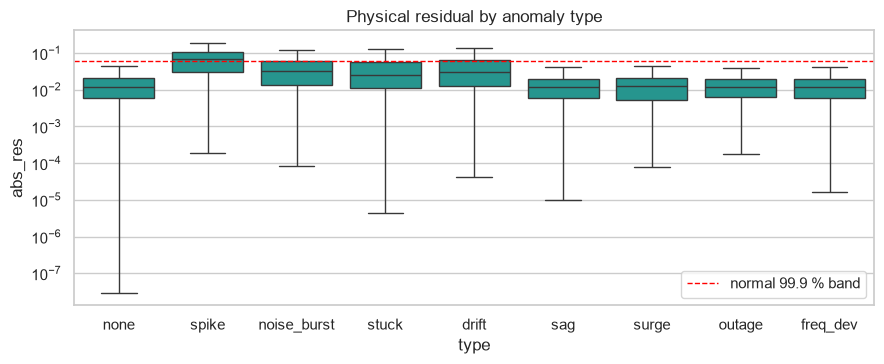

In [7]:
# ------------------------------------------------------------------
# Step 6: Residual of the physical relation, by anomaly type.
# ------------------------------------------------------------------
res = obs["p"] / el.power_from_vi(obs["v"], obs["i"], obs["pf"]) - 1.0
res_clean = clean["p"] / el.power_from_vi(clean["v"], clean["i"], clean["pf"]) - 1.0
band = np.quantile(np.abs(res_clean), 0.999)                  # 99.9 % band of normal operation

df_res = pd.DataFrame({"type": pd.Series(type_code.ravel()).map(NAMES).values,
                       "abs_res": np.abs(res).ravel()})
summary_res = (df_res.groupby("type")["abs_res"]
               .agg(median="median", p95=lambda x: x.quantile(0.95),
                    share_outside_band=lambda x: (x > band).mean())
               .round(4).sort_values("share_outside_band", ascending=False))
print(f"Normal 99.9 % band of |residual|: {band:.4f}")
display(summary_res)

plt.figure(figsize=(9, 3.8))
order = [k for k in CODES if k in summary_res.index]
sns.boxplot(data=df_res.sample(min(len(df_res), 300_000), random_state=SEED), x="type", y="abs_res",
            order=order, showfliers=False, color="#13A89E")
plt.axhline(band, color="red", ls="--", lw=1, label="normal 99.9 % band")
plt.yscale("log"); plt.legend(); plt.title("Physical residual by anomaly type")
plt.tight_layout(); savefig("05_residual_by_type"); plt.show()

## Step 7 - Visual check of each anomaly type

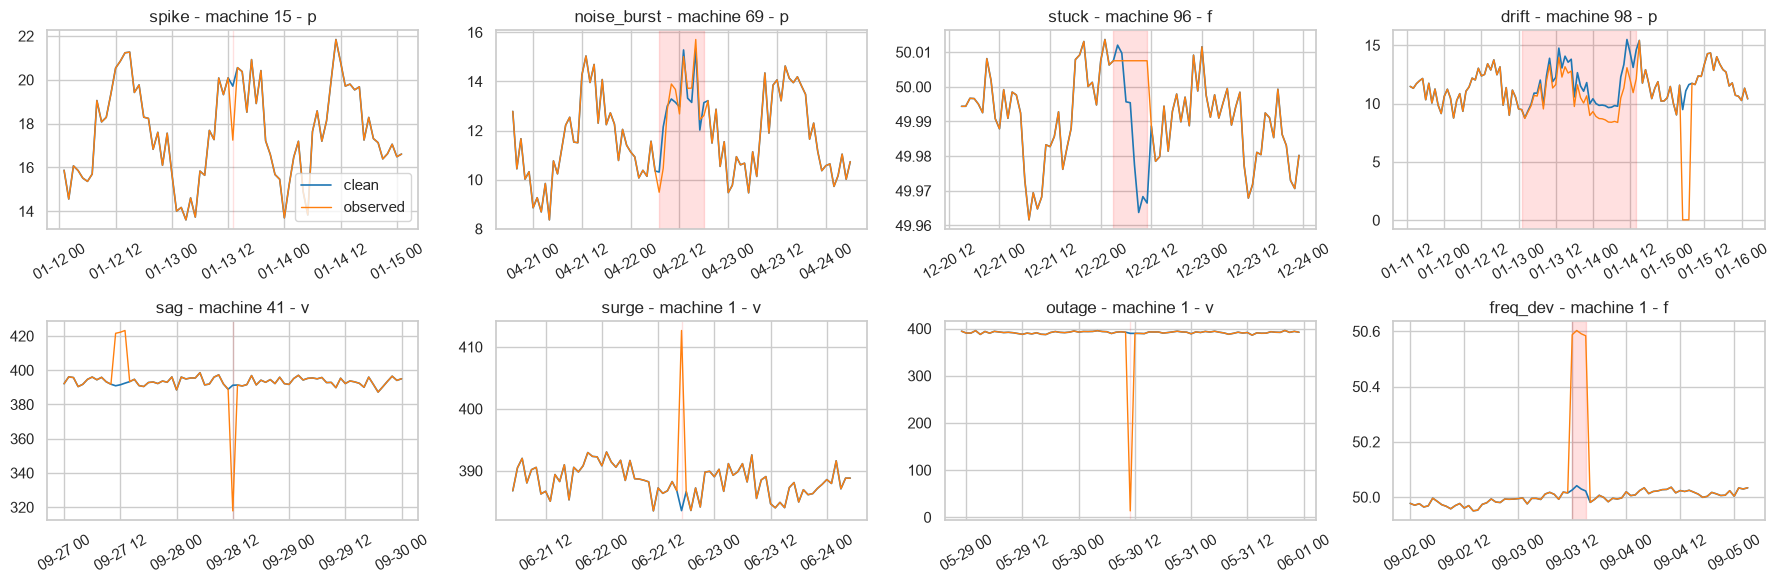

In [8]:
# ------------------------------------------------------------------
# Step 7: One example per type: clean (blue) vs. observed (orange)
# on the most relevant channel, with the anomaly window shaded.
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for ax, kind in zip(axes.ravel(), [k for k in CODES if k != "none"]):
    ev = events[events["type"] == kind]
    if ev.empty:
        ax.set_visible(False); continue
    e = ev.iloc[0]
    m = (int(np.where(machine_ids == e["machine"])[0][0]) if e["machine"] > 0
         else int(np.where(grid_code[:, e["start"]] == CODES[kind])[0][0]))
    s = e["sensor"] if e["sensor"] in SENSORS else "v"
    lo, hi = max(0, e["start"] - 36), min(T, e["end"] + 37)
    ax.plot(dt[lo:hi], clean[s][m, lo:hi], lw=1.2, color="tab:blue", label="clean")
    ax.plot(dt[lo:hi], obs[s][m, lo:hi], lw=1.0, color="tab:orange", label="observed")
    ax.axvspan(dt[e["start"]], dt[e["end"]], color="red", alpha=0.12)
    ax.set_title(f"{kind} - machine {machine_ids[m]} - {s}")
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend()
plt.tight_layout(); savefig("05_examples"); plt.show()

## Step 8 - Cross-machine signature of grid events

A grid event must show up on many machines at once, a sensor fault on one. We count how many machines are anomalous at each hour.

In [9]:
# ------------------------------------------------------------------
# Step 8: Number of anomalous machines per hour, by family.
# ------------------------------------------------------------------
n_grid = label_grid.sum(axis=0)
n_sens = label_sensor.sum(axis=0)
print("Grid events  : machines affected per event -> ",
      events.loc[events["family"] == "grid_event", "n_machines"].describe()[["min", "50%", "max"]].to_dict())
print("Sensor faults: max simultaneous faulty machines at one hour =", int(n_sens.max()))
print("Hours with at least one grid event:", int((n_grid > 0).sum()),
      "| hours with at least one sensor fault:", int((n_sens > 0).sum()))

Grid events  : machines affected per event ->  {'min': 20.0, '50%': 20.0, 'max': 100.0}
Sensor faults: max simultaneous faulty machines at one hour = 7
Hours with at least one grid event: 203 | hours with at least one sensor fault: 4833


## Step 9 - Save the dataset, the events and the parameters

In [10]:
# ------------------------------------------------------------------
# Step 9: Assemble the long table (machine-major order, same as the
# baseline) and save it. Clean values are kept (*_meas) next to the
# observed ones (*_obs) so detectors can be scored against the truth.
# ------------------------------------------------------------------
f32 = lambda a: np.asarray(a, dtype=np.float32).ravel()

out = pd.DataFrame({
    "datetime": base["datetime"].values, "machineID": base["machineID"].values,
    "line": base["line"].values,
    **{f"{s}_meas": f32(clean[s]) for s in SENSORS},
    **{f"{s}_obs": f32(obs[s]) for s in SENSORS},
    "label_sensor_fault": label_sensor.ravel(), "label_grid_event": label_grid.ravel(),
    "label_any": (label_sensor | label_grid).ravel().astype(np.int8),
    "anomaly_type": pd.Series(type_code.ravel()).map(NAMES).values,
    "anomaly_sensor": anom_sensor.ravel(), "event_id": event_id.ravel(),
})

def save_table(df, name):
    try:
        df.to_parquet(SIMULATED / f"{name}.parquet", index=False); return "parquet"
    except Exception as e:
        df.to_pickle(SIMULATED / f"{name}.pkl"); return f"pickle ({type(e).__name__})"

print("anomaly_dataset saved as", save_table(out, "anomaly_dataset"), "| shape", out.shape)
events.to_csv(SIMULATED / "anomaly_events.csv", index=False)

params = {**{k: v for k, v in ANOM.items()}, "sig": SIG, "codes": CODES}
(LOGS / "anomaly_params.json").write_text(json.dumps(params, indent=2, default=str), encoding="utf-8")
print("Events:", len(events), "| parameters saved to logs/anomaly_params.json")

anomaly_dataset saved as parquet | shape (876100, 19)
Events: 788 | parameters saved to logs/anomaly_params.json


## Summary and next step

* Two labelled families of anomalies now sit on top of the measured layer: **local sensor faults** (spike, noise burst, stuck, drift) and **simultaneous grid events** (sag, surge, outage, frequency deviation).
* Grid events keep `P = sqrt(3) V I PF` consistent and hit many machines at once; sensor faults on `v`, `i`, `p`, `pf` break the relation on a single machine.
* Frequency faults are not covered by the power relation: they need a cross-machine check.
* Next: score the detectors on `anomaly_dataset` with the events table as ground truth.